# 02 · Build X and Y

This notebook builds the matrices used by every model:
- **X:** the expression of each tumor, with **the same genes in the same order** in the four cohorts.
- **Y:** the TP53 status (1 = mutated, 0 = WT), as it was defined in notebook 01.

The steps are the following:
1. Keep the tumors that have a label.
2. Map each expression row to its Entrez ID.
3. Keep the protein-coding genes shared by the four cohorts, without TP53.
4. If a gene has more than one row, keep **the one with the highest mean expression** (decision of 06-Oct-2026).
5. Move RNA-seq to log2(TPM + 1). METABRIC is already in log2.

**What is NOT done here:** the normalization (z-score). It uses statistics of the training patients, so it is computed later, inside notebooks 05 to 08.

**Input:** `data/raw/` and the outputs of notebook 01 (`data/processed/revision/`).
**Output:** `data/processed/X_<cohort>.parquet` and `data/processed/y_<cohort>.csv`.

*Note: this notebook was run before the repository was translated. The code comments, printed text and figure labels in the saved outputs are in Spanish. The results are the same.*

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
REV = ROOT / "data" / "processed" / "revision"
OUT = ROOT / "data" / "processed"

COHORTS = {
    "TCGA-BRCA": ("brca_tcga_gdc", "data_mrna_seq_tpm.txt", "RNA-seq"),
    "METABRIC": ("brca_metabric", "data_mrna_illumina_microarray.txt", "microarreglo"),
    "CPTAC": ("breast_cptac_gdc", "data_mrna_seq_tpm.txt", "RNA-seq"),
    "SMC 2018": ("brca_smc_2018", "data_mrna_seq_tpm.txt", "RNA-seq"),
}
FILE_NAME = {"TCGA-BRCA": "tcga_brca", "METABRIC": "metabric", "CPTAC": "cptac", "SMC 2018": "smc_2018"}
COLORS = {"TCGA-BRCA": "#1D9E75", "METABRIC": "#5DCAA5", "CPTAC": "#534AB7", "SMC 2018": "#AFA9EC"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

labels = pd.read_csv(REV / "etiquetas_tp53.csv")
labels = labels[labels.tp53_status != "Excluido"].copy()
labels["y"] = (labels.tp53_status == "Mutado").astype(int)
genes = pd.read_csv(REV / "genes_comunes_codificantes.csv").entrez_gene_id.astype(int).tolist()
smc_translation = pd.read_csv(REV / "smc_traduccion_nombres.csv")

print("Tumores con etiqueta:", len(labels))
print("Genes comunes codificantes (sin TP53):", len(genes))

Tumores con etiqueta: 3132
Genes comunes codificantes (sin TP53): 18040


## Step 1 · Read the expression and map it to Entrez IDs

Each cohort stores the genes in a different way (see notebook 01). Here the full matrix is read, only with the labeled tumors, and each row gets its Entrez ID. In SMC the symbol translation of notebook 01 is used, with the old symbols replaced by the new ones.

In [2]:
def read_expression(name):
    study, file, _ = COHORTS[name]
    keep = set(labels.loc[labels.cohort == name, "sample_id"])
    e = pd.read_csv(RAW / study / file, sep="\t", usecols=lambda c: c in keep | {"Hugo_Symbol", "Entrez_Gene_Id"})
    if e["Entrez_Gene_Id"].isna().all():
        e["Entrez_Gene_Id"] = e["Hugo_Symbol"].map(dict(zip(smc_translation.hugo_symbol_smc, smc_translation.entrez)))
    e = e.dropna(subset=["Entrez_Gene_Id"]).drop(columns="Hugo_Symbol", errors="ignore")
    e["Entrez_Gene_Id"] = e["Entrez_Gene_Id"].astype(int)
    return e.set_index("Entrez_Gene_Id")


raw = {}
for name in COHORTS:
    raw[name] = read_expression(name)
    print(f"{name}: {raw[name].shape[0]} filas × {raw[name].shape[1]} tumores")

TCGA-BRCA: 40796 filas × 961 tumores


METABRIC: 20603 filas × 1899 tumores


CPTAC: 40796 filas × 105 tumores


SMC 2018: 21238 filas × 167 tumores


## Step 2 · Shared genes and one row per gene

Some genes appear in more than one row:
- In **METABRIC**, because the microarray measures some genes with two probes. For example, BIRC5 has two rows with different values.
- In **TCGA and CPTAC**, because two Ensembl IDs point to the same Entrez ID.
- In **SMC**, because translating the old symbols sometimes leaves two rows for the same gene.

**Rule (06-Oct-2026):** keep the row with the **highest mean expression** in that cohort. It is the rule that [Miller et al. 2011](https://doi.org/10.1186/1471-2105-12-322) found most consistent to **join studies from different platforms**. It does not use the TP53 label, so there is no leakage.

In [3]:
def one_row_per_gene(e):
    """Si un gen tiene varias filas, deja la de mayor expresión promedio."""
    mean = e.mean(axis=1)
    order = mean.sort_values(ascending=False).index
    ranked = e.loc[order]
    return ranked[~ranked.index.duplicated(keep="first")]


X = {}
rows = []
for name, e in raw.items():
    e = e[e.index.isin(genes)]
    dup_genes = e.index[e.index.duplicated()].nunique()
    collapsed = one_row_per_gene(e)
    X[name] = collapsed.reindex(genes).T
    rows.append({"Cohorte": name, "Filas de genes comunes": len(e), "Genes con más de una fila": dup_genes,
                 "Genes al final": X[name].shape[1], "Tumores": X[name].shape[0]})
pd.DataFrame(rows).set_index("Cohorte")

,Filas de genes comunes,Genes con más de una fila,Genes al final,Tumores
Cohorte,,,,
TCGA-BRCA,18044,4,18040,961
METABRIC,18320,270,18040,1899
CPTAC,18044,4,18040,105
SMC 2018,18107,63,18040,167


### Example: a gene with two probes in METABRIC
This is how the rule looks in a real case. The probe with the highest mean is kept.

In [4]:
mb_raw = raw["METABRIC"]
example = 332   # BIRC5
probes = mb_raw.loc[[example]]
pd.DataFrame({"Sonda": [f"sonda {i + 1}" for i in range(len(probes))], "Expresión promedio": probes.mean(axis=1).round(2).values,
              "Se queda": probes.mean(axis=1).values == probes.mean(axis=1).max()})

,Sonda,Expresión promedio,Se queda
0,sonda 1,7.13,True
1,sonda 2,5.43,False


## Step 3 · Logarithmic scale

- **RNA-seq (TCGA, CPTAC, SMC):** log2(TPM + 1). The log compresses the range of TPM, which goes from 0 to tens of thousands. The +1 avoids the log of 0.
- **METABRIC:** it already comes as log2 microarray intensity. It is not changed.

In [5]:
for name, (_, _, platform) in COHORTS.items():
    if platform == "RNA-seq":
        X[name] = np.log2(X[name] + 1)

summary = pd.DataFrame({name: {"Mínimo": x.min().min(), "Mediana": float(np.nanmedian(x.values)),
                               "Máximo": x.max().max(), "Genes con algún vacío": int(x.isna().any().sum()),
                               "Valores vacíos": int(x.isna().sum().sum())}
                        for name, x in X.items()}).T.round(2)
summary

,Mínimo,Mediana,Máximo,Genes con algún vacío,Valores vacíos
TCGA-BRCA,0.00,3.23,17.82,0.0,0.0
METABRIC,4.56,6.25,14.88,11.0,14.0
CPTAC,0.00,3.10,15.93,0.0,0.0
SMC 2018,0.00,3.03,16.81,0.0,0.0


## Step 4 · Why a normalization is still needed

The four cohorts now have the same genes, but they are **not comparable yet**. The same gene can be 3 in TCGA and 8 in METABRIC only because of the platform. The figure shows ESR1, the estrogen receptor gene.
- **Left:** after log2. METABRIC is shifted because it is a microarray.
- **Right:** with a z-score inside each cohort (the main normalization). The four end up on the same scale. Here it is computed with all tumors **only to illustrate it**. In the experiment it is computed with the training patients.

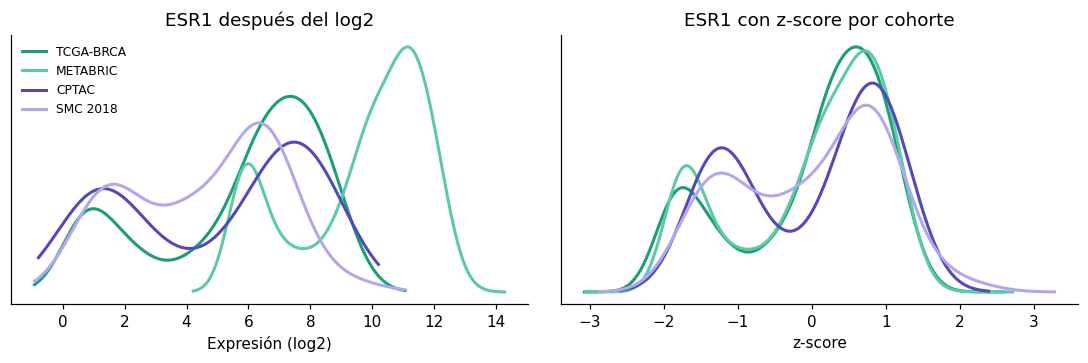

In [6]:
from scipy.stats import gaussian_kde

ESR1 = 2099
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, x in X.items():
    v = x[ESR1].dropna().values
    z = (v - v.mean()) / v.std()
    for ax, values in [(axes[0], v), (axes[1], z)]:
        grid = np.linspace(values.min() - 1, values.max() + 1, 300)
        ax.plot(grid, gaussian_kde(values)(grid), lw=2, color=COLORS[name], label=name)
axes[0].set_title("ESR1 después del log2")
axes[1].set_title("ESR1 con z-score por cohorte")
axes[0].set_xlabel("Expresión (log2)")
axes[1].set_xlabel("z-score")
for a in axes:
    a.set_yticks([])
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

ESR1 has two peaks in every cohort: ER negative tumors (low expression) and ER positive tumors (high expression). On the left, the peaks are in different places depending on the platform. On the right, they are aligned. The size of each peak is still different, because each cohort has a different mix of subtypes. This is the weak point of the z-score that Foltz et al. (2023) described.

## Step 5 · Save X and Y

Each cohort is saved in two files:
- `X_<cohort>.parquet`: one row per tumor, one column per gene (Entrez ID), in the same order in the four cohorts.
- `y_<cohort>.csv`: the TP53 status of each tumor (1 = mutated, 0 = WT), with its patient ID and its PAM50 subtype.

In [7]:
check_order = all(list(x.columns) == genes for x in X.values())
print("¿Mismos genes en el mismo orden en las cuatro?", check_order)

final = []
for name, x in X.items():
    y = labels[labels.cohort == name].set_index("sample_id").loc[x.index, ["patient_id", "y", "pam50"]]
    x.columns = x.columns.astype(str)
    x.astype("float32").to_parquet(OUT / f"X_{FILE_NAME[name]}.parquet")
    y.to_csv(OUT / f"y_{FILE_NAME[name]}.csv")
    final.append({"Cohorte": name, "Tumores": len(x), "Genes": x.shape[1], "Mutados": int(y.y.sum()),
                  "WT": int((1 - y.y).sum()), "% mutado": round(100 * y.y.mean(), 1),
                  "Archivo X": f"X_{FILE_NAME[name]}.parquet"})
pd.DataFrame(final).set_index("Cohorte")

¿Mismos genes en el mismo orden en las cuatro? True


,Tumores,Genes,Mutados,WT,% mutado,Archivo X
Cohorte,,,,,,
TCGA-BRCA,961,18040,331,630,34.4,X_tcga_brca.parquet
METABRIC,1899,18040,659,1240,34.7,X_metabric.parquet
CPTAC,105,18040,41,64,39.0,X_cptac.parquet
SMC 2018,167,18040,81,86,48.5,X_smc_2018.parquet


## What was decided after this notebook

1. METABRIC has a few missing values (14, in 11 genes). They are filled with the median of the gene in the training patients (`common.zscore`).
2. The normalization (z-score inside each cohort) is applied in notebooks 05 to 08, with the training patients of each case.